## import the segment wise absolute correlation matrices

In [1]:
from pathlib import Path
import pandas as pd

abs_segment_base = Path('../correlation_matrices_segment_wise_absolute')
matrix_files = list(abs_segment_base.rglob('*.csv'))

if matrix_files:
    sample = pd.read_csv(matrix_files[0], index_col=0)
    print(f"Found {len(matrix_files)} absolute matrices. Sample shape: {sample.shape}")


Found 2632 absolute matrices. Sample shape: (19, 19)


## filter the subjects for our study

In [2]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations

# Filter subjects
subject_ids = [64, 65, 69, 70, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 89, 90, 94, 96, 103]
formatted_subjects = [f"sub-NORB{sid:05d}" for sid in subject_ids]

# Extract first 12 segments for session 1
n_segments = 12
subject_matrices = {}

for subj in formatted_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    if not subj_dir.exists():
        print(f"Warning: directory not found for {subj}")
        continue
        
    csv_files = sorted(subj_dir.glob('*.csv'))
    if len(csv_files) < n_segments:
        print(f"Warning: {subj} has less than {n_segments} segments")
        
    matrices = []
    for csv_file in csv_files[:n_segments]:
        df = pd.read_csv(csv_file, index_col=0)
        matrices.append(df.values)
        
    if matrices:
        avg_matrix = np.mean(matrices, axis=0)
        subject_matrices[subj] = pd.DataFrame(avg_matrix, index=df.index, columns=df.columns)
        
print(f"Processed {len(subject_matrices)} subjects")


Processed 20 subjects


## plotting raw correlation data

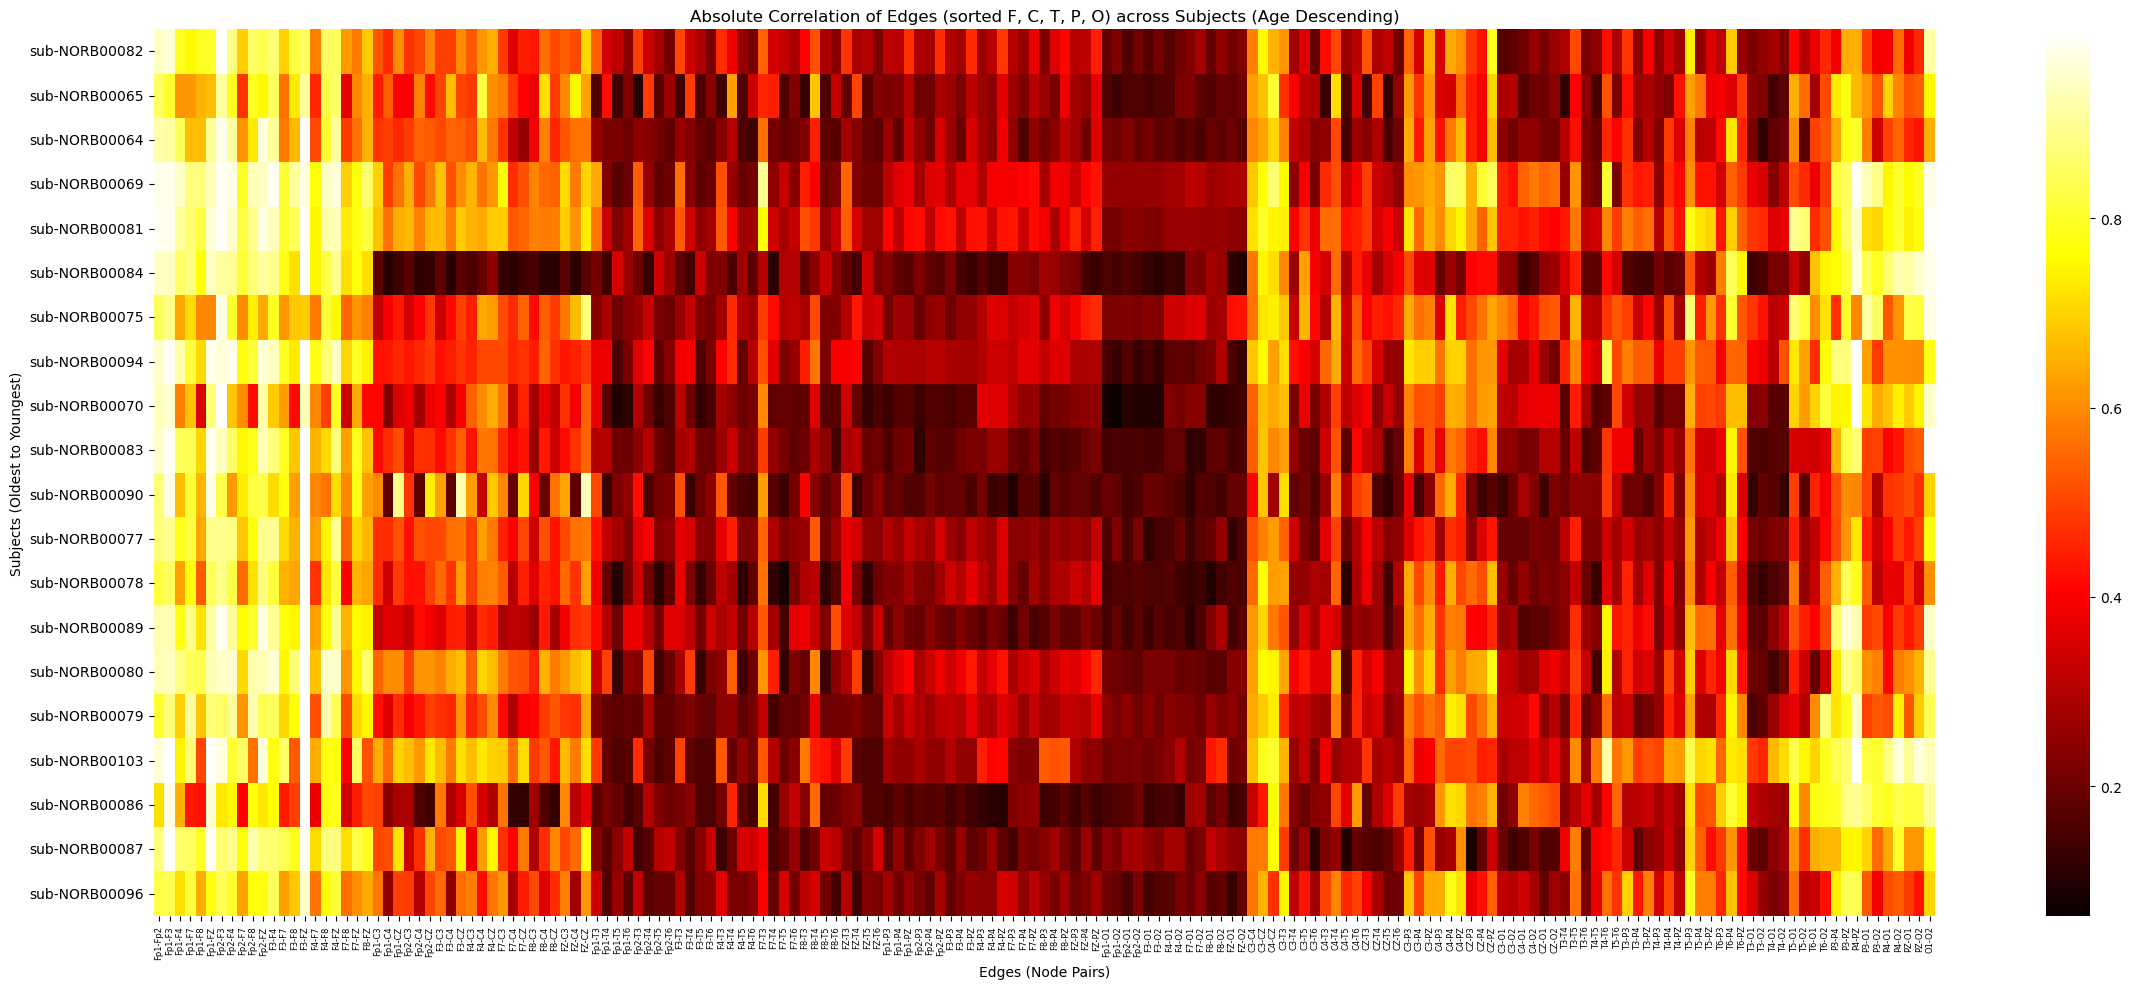

In [3]:
# Hardcoded edge order (F, C, T, P, O pairs)
edge_labels = [
    'Fp1-Fp2', 'Fp1-F3', 'Fp1-F4', 'Fp1-F7', 'Fp1-F8', 'Fp1-FZ', 'Fp2-F3',
    'Fp2-F4', 'Fp2-F7', 'Fp2-F8', 'Fp2-FZ', 'F3-F4', 'F3-F7', 'F3-F8', 'F3-FZ',
    'F4-F7', 'F4-F8', 'F4-FZ', 'F7-F8', 'F7-FZ', 'F8-FZ', 'Fp1-C3', 'Fp1-C4',
    'Fp1-CZ', 'Fp2-C3', 'Fp2-C4', 'Fp2-CZ', 'F3-C3', 'F3-C4', 'F3-CZ', 'F4-C3',
    'F4-C4', 'F4-CZ', 'F7-C3', 'F7-C4', 'F7-CZ', 'F8-C3', 'F8-C4', 'F8-CZ',
    'FZ-C3', 'FZ-C4', 'FZ-CZ', 'Fp1-T3', 'Fp1-T4', 'Fp1-T5', 'Fp1-T6',
    'Fp2-T3', 'Fp2-T4', 'Fp2-T5', 'Fp2-T6', 'F3-T3', 'F3-T4', 'F3-T5', 'F3-T6',
    'F4-T3', 'F4-T4', 'F4-T5', 'F4-T6', 'F7-T3', 'F7-T4', 'F7-T5', 'F7-T6',
    'F8-T3', 'F8-T4', 'F8-T5', 'F8-T6', 'FZ-T3', 'FZ-T4', 'FZ-T5', 'FZ-T6',
    'Fp1-P3', 'Fp1-P4', 'Fp1-PZ', 'Fp2-P3', 'Fp2-P4', 'Fp2-PZ', 'F3-P3',
    'F3-P4', 'F3-PZ', 'F4-P3', 'F4-P4', 'F4-PZ', 'F7-P3', 'F7-P4', 'F7-PZ',
    'F8-P3', 'F8-P4', 'F8-PZ', 'FZ-P3', 'FZ-P4', 'FZ-PZ', 'Fp1-O1', 'Fp1-O2',
    'Fp2-O1', 'Fp2-O2', 'F3-O1', 'F3-O2', 'F4-O1', 'F4-O2', 'F7-O1', 'F7-O2',
    'F8-O1', 'F8-O2', 'FZ-O1', 'FZ-O2', 'C3-C4', 'C3-CZ', 'C4-CZ', 'C3-T3',
    'C3-T4', 'C3-T5', 'C3-T6', 'C4-T3', 'C4-T4', 'C4-T5', 'C4-T6', 'CZ-T3',
    'CZ-T4', 'CZ-T5', 'CZ-T6', 'C3-P3', 'C3-P4', 'C3-PZ', 'C4-P3', 'C4-P4',
    'C4-PZ', 'CZ-P3', 'CZ-P4', 'CZ-PZ', 'C3-O1', 'C3-O2', 'C4-O1', 'C4-O2',
    'CZ-O1', 'CZ-O2', 'T3-T4', 'T3-T5', 'T3-T6', 'T4-T5', 'T4-T6', 'T5-T6',
    'T3-P3', 'T3-P4', 'T3-PZ', 'T4-P3', 'T4-P4', 'T4-PZ', 'T5-P3', 'T5-P4',
    'T5-PZ', 'T6-P3', 'T6-P4', 'T6-PZ', 'T3-O1', 'T3-O2', 'T4-O1', 'T4-O2',
    'T5-O1', 'T5-O2', 'T6-O1', 'T6-O2', 'P3-P4', 'P3-PZ', 'P4-PZ', 'P3-O1',
    'P3-O2', 'P4-O1', 'P4-O2', 'PZ-O1', 'PZ-O2', 'O1-O2',
]

# Load ages and sort subjects descending (oldest top, youngest bottom)
ages_df = pd.read_csv('../age_acq_time_sorted.csv')
target_labels = [f"{subj}_ses-1" for subj in formatted_subjects]
ages_filtered = ages_df[ages_df['label'].isin(target_labels)].copy()
ages_filtered = ages_filtered.sort_values('age_acq_time', ascending=False)

sorted_subject_labels = ages_filtered['label'].tolist()
sorted_subjects = [label.split('_')[0] for label in sorted_subject_labels]

# Prepare data for heatmap
heatmap_data = []
valid_subjects = []

for subj in sorted_subjects:
    if subj in subject_matrices:
        df_matrix = subject_matrices[subj]
        row_data = [df_matrix.loc[e.split('-')[0], e.split('-')[1]] for e in edge_labels]
        heatmap_data.append(row_data)
        valid_subjects.append(subj)

heatmap_data = np.array(heatmap_data)

# Plot heatmap
plt.figure(figsize=(24, 10))
sns.heatmap(heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=valid_subjects)
plt.title('Absolute Correlation of Edges (sorted F, C, T, P, O) across Subjects (Age Descending)')
plt.xlabel('Edges (Node Pairs)')
plt.ylabel('Subjects (Oldest to Youngest)')
plt.xticks(rotation=90, fontsize=6)
plt.tight_layout()
plt.show()


## edge-wise weighted jaccard index
for each pair of subjects and for each of the 171 edges, it:
1. calculates the jaccard index `min(A, B) / max(A, B)` for that specific edge on a given segment.
2. averages this edge-specific jaccard index across all 12 segments.

the result is a dictionary mapping each subject pair `(subj1, subj2)` to an array of 171 average jaccard index values (one for each edge).


In [4]:
# Load all 12 segment matrices for the valid subjects to calculate the Jaccard Index
subject_segments = {}
for subj in valid_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    csv_files = sorted(subj_dir.glob('*.csv'))[:12]
    
    seg_list = []
    for csv_file in csv_files:
        df = pd.read_csv(csv_file, index_col=0)
        # Extract the exact 171 edges defined earlier
        edge_vals = [df.loc[e.split('-')[0], e.split('-')[1]] for e in edge_labels]
        seg_list.append(np.array(edge_vals))
    subject_segments[subj] = seg_list

# Calculate edge-wise Jaccard index for all subject pairs (20C2)
subject_pairs = list(combinations(valid_subjects, 2))
pair_edgewise_jaccard = {}

for subj1, subj2 in subject_pairs:
    segment_edge_jaccards = []
    
    for k in range(12):
        u = subject_segments[subj1][k]  # Array of 171 edges for segment k
        v = subject_segments[subj2][k]
        
        # Edge-wise Jaccard: min(u_i, v_i) / max(u_i, v_i) for each edge
        mins = np.minimum(u, v)
        maxs = np.maximum(u, v)
        
        # Handle division by zero per edge securely
        with np.errstate(divide='ignore', invalid='ignore'):
            j_score = np.where(maxs != 0, mins / maxs, 0)
            
        segment_edge_jaccards.append(j_score)
        
    # Average across the 12 segments for this pair, resulting in 171 averaged values
    pair_edgewise_jaccard[(subj1, subj2)] = np.mean(segment_edge_jaccards, axis=0)

print(f"Calculated edge-wise Jaccard indices for {len(pair_edgewise_jaccard)} subject pairs.")
print(f"Each pair has {len(list(pair_edgewise_jaccard.values())[0])} values corresponding to the edges.")


Calculated edge-wise Jaccard indices for 190 subject pairs.
Each pair has 171 values corresponding to the edges.


## plot the jaccard index

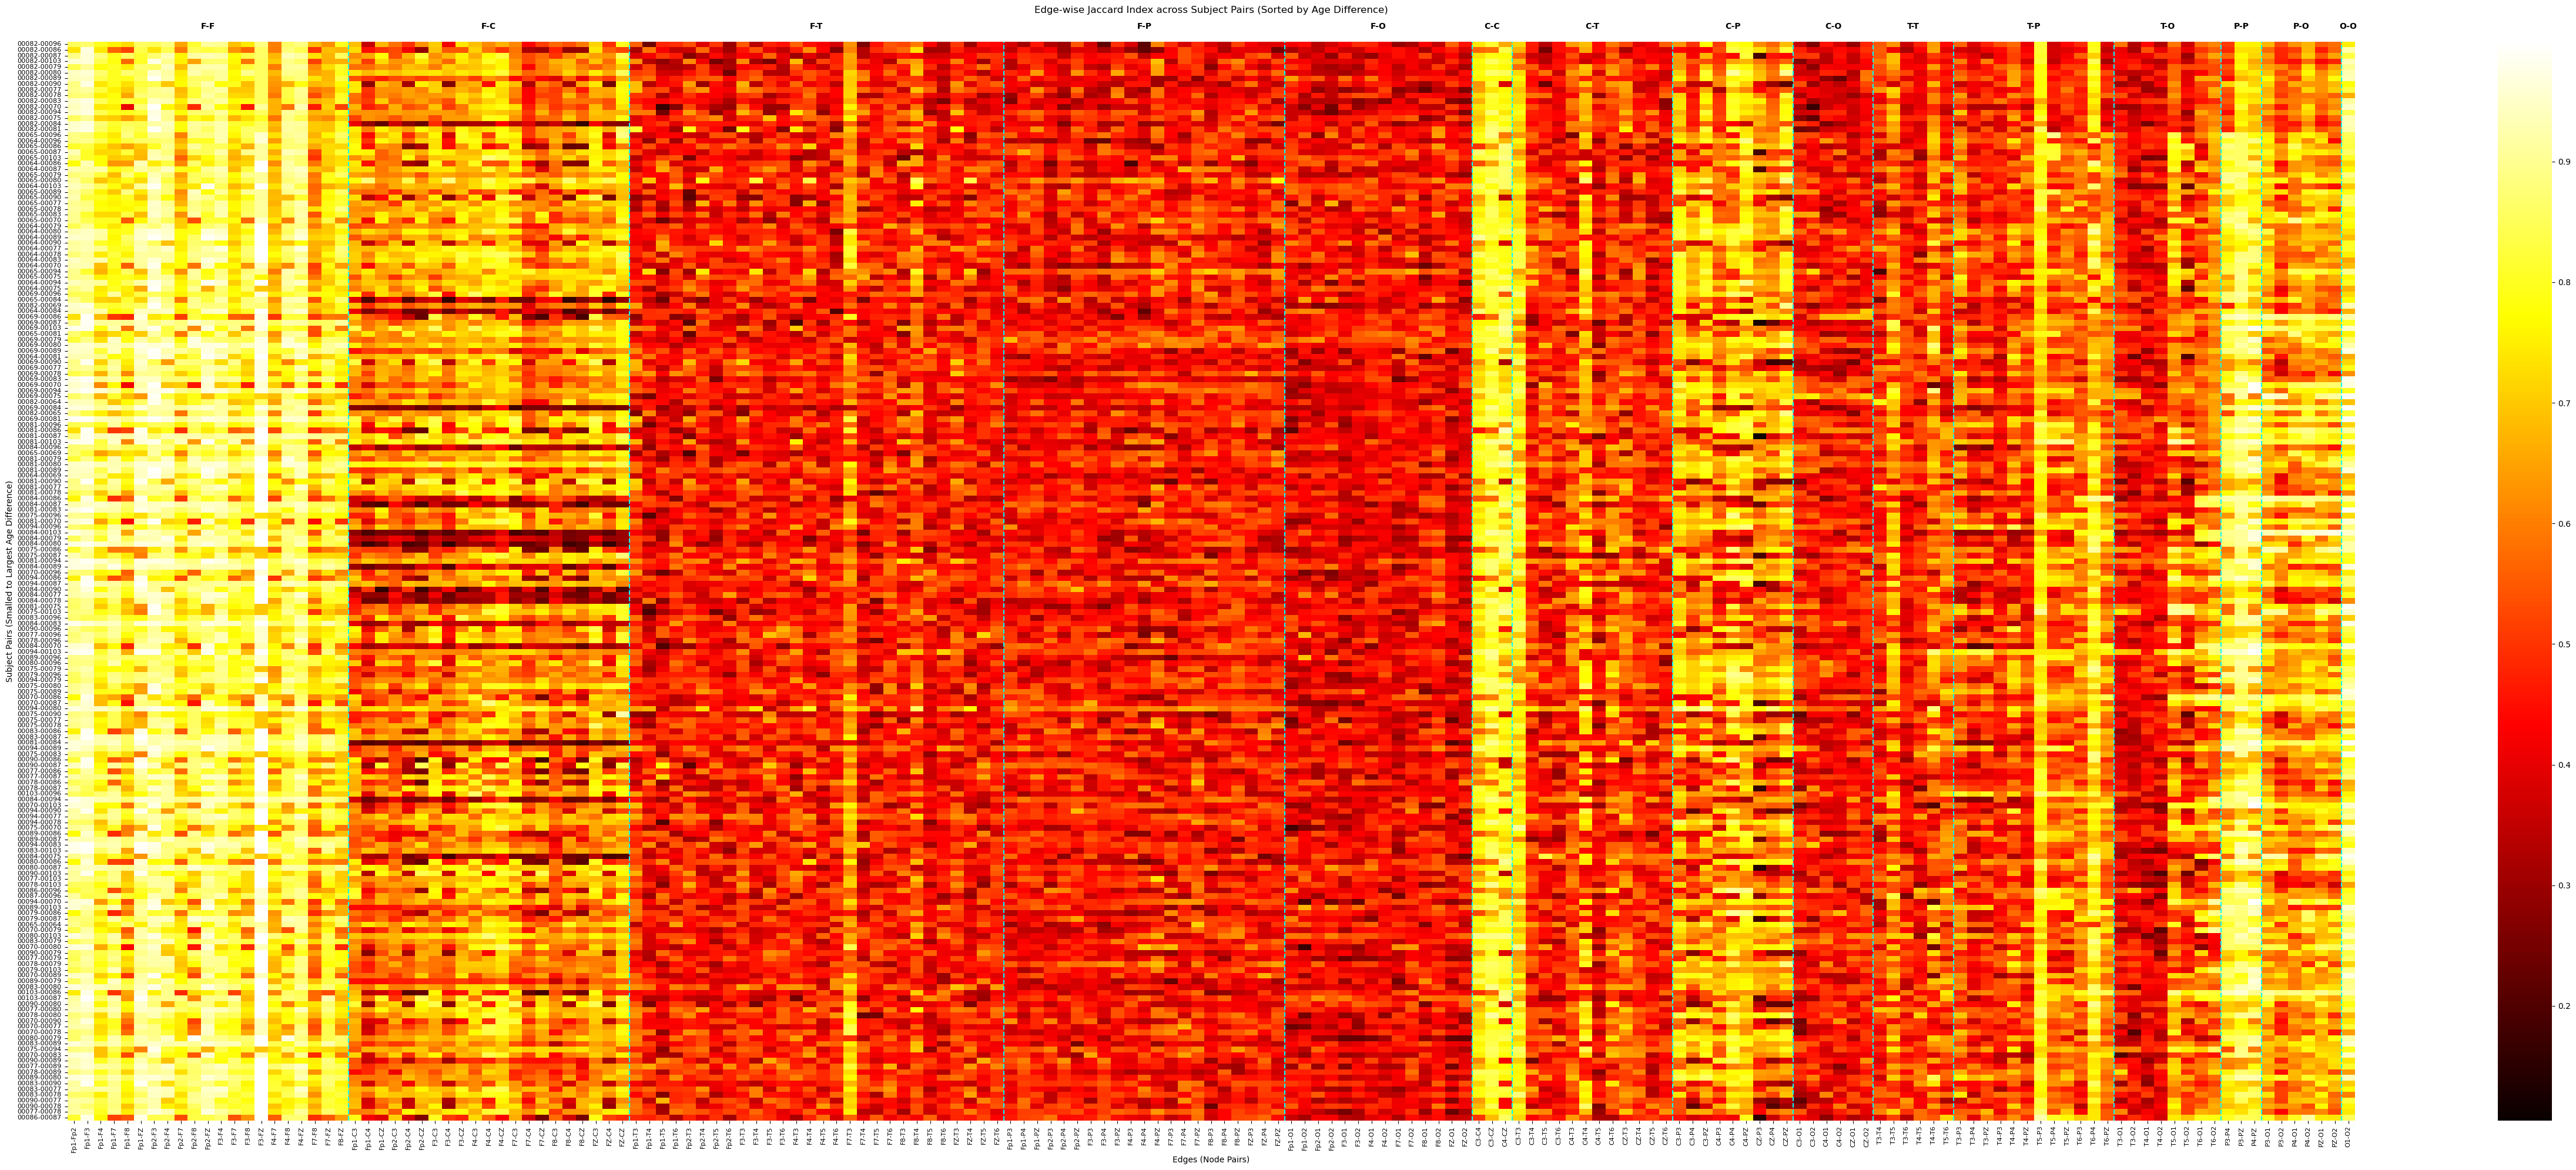

In [5]:
# Create a dictionary mapping subject ID to their age
age_dict = {}
for idx, row in ages_filtered.iterrows():
    subj = row['label'].split('_')[0]
    age_dict[subj] = row['age_acq_time']

# Compute absolute age differences for each subject pair
pair_age_diffs = {}
for subj1, subj2 in subject_pairs:
    diff = abs(age_dict[subj1] - age_dict[subj2])
    pair_age_diffs[(subj1, subj2)] = diff

# Sort subject pairs by age difference (descending: largest difference at top, smallest at bottom)
sorted_pairs = sorted(pair_age_diffs.keys(), key=lambda p: pair_age_diffs[p], reverse=True)

# Prepare data for heatmap
heatmap_data = []
yticklabels = []

for pair in sorted_pairs:
    heatmap_data.append(pair_edgewise_jaccard[pair])
    # Create a compact label for the y-axis
    s1 = pair[0].replace('sub-NORB', '')
    s2 = pair[1].replace('sub-NORB', '')
    yticklabels.append(f"{s1}-{s2}")

heatmap_data = np.array(heatmap_data)

# Plot the heatmap with a wide figure size to stretch the cells horizontally
plt.figure(figsize=(50, 20)) 
sns.heatmap(heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=yticklabels)

# labels of the region pair at the top of the heatmap
import matplotlib.transforms as transforms

ax = plt.gca()
# Combine X in data coordinates (columns) with Y in axes coordinates (plot box height)
trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)

start_idx = 0
for i in range(1, len(edge_labels) + 1):
    r_prev = f"{edge_labels[i-1].split('-')[0][0]}-{edge_labels[i-1].split('-')[1][0]}"
    r_curr = f"{edge_labels[i].split('-')[0][0]}-{edge_labels[i].split('-')[1][0]}" if i < len(edge_labels) else None
    
    if r_prev != r_curr:
        # 1. Draw vertical boundary line between region groups
        if i < len(edge_labels):
            ax.axvline(x=i, color='cyan', linestyle='--', linewidth=1.5)
            
        # 2. Calculate horizontal center of this region group
        mid_x = (start_idx + i) / 2.0
        
        # 3. Place label slightly above the top edge of the plot (y=1.01 in axes coordinates)
        ax.text(mid_x, 1.01, r_prev, transform=trans, ha='center', va='bottom', fontsize=10, fontweight='bold')
        
        start_idx = i


plt.title('Edge-wise Jaccard Index across Subject Pairs (Sorted by Age Difference)', pad=35)
plt.xlabel('Edges (Node Pairs)')
plt.ylabel('Subject Pairs (Smalled to Largest Age Difference)')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


## Region-wise Statistical Summary of Jaccard Index Values

This cell calculates and displays a grouped bar plot showing the percentage of Jaccard index values exceeding **0.75** and **0.90** for each specific brain region connection type (F-F, F-C, F-T, ..., O-O).

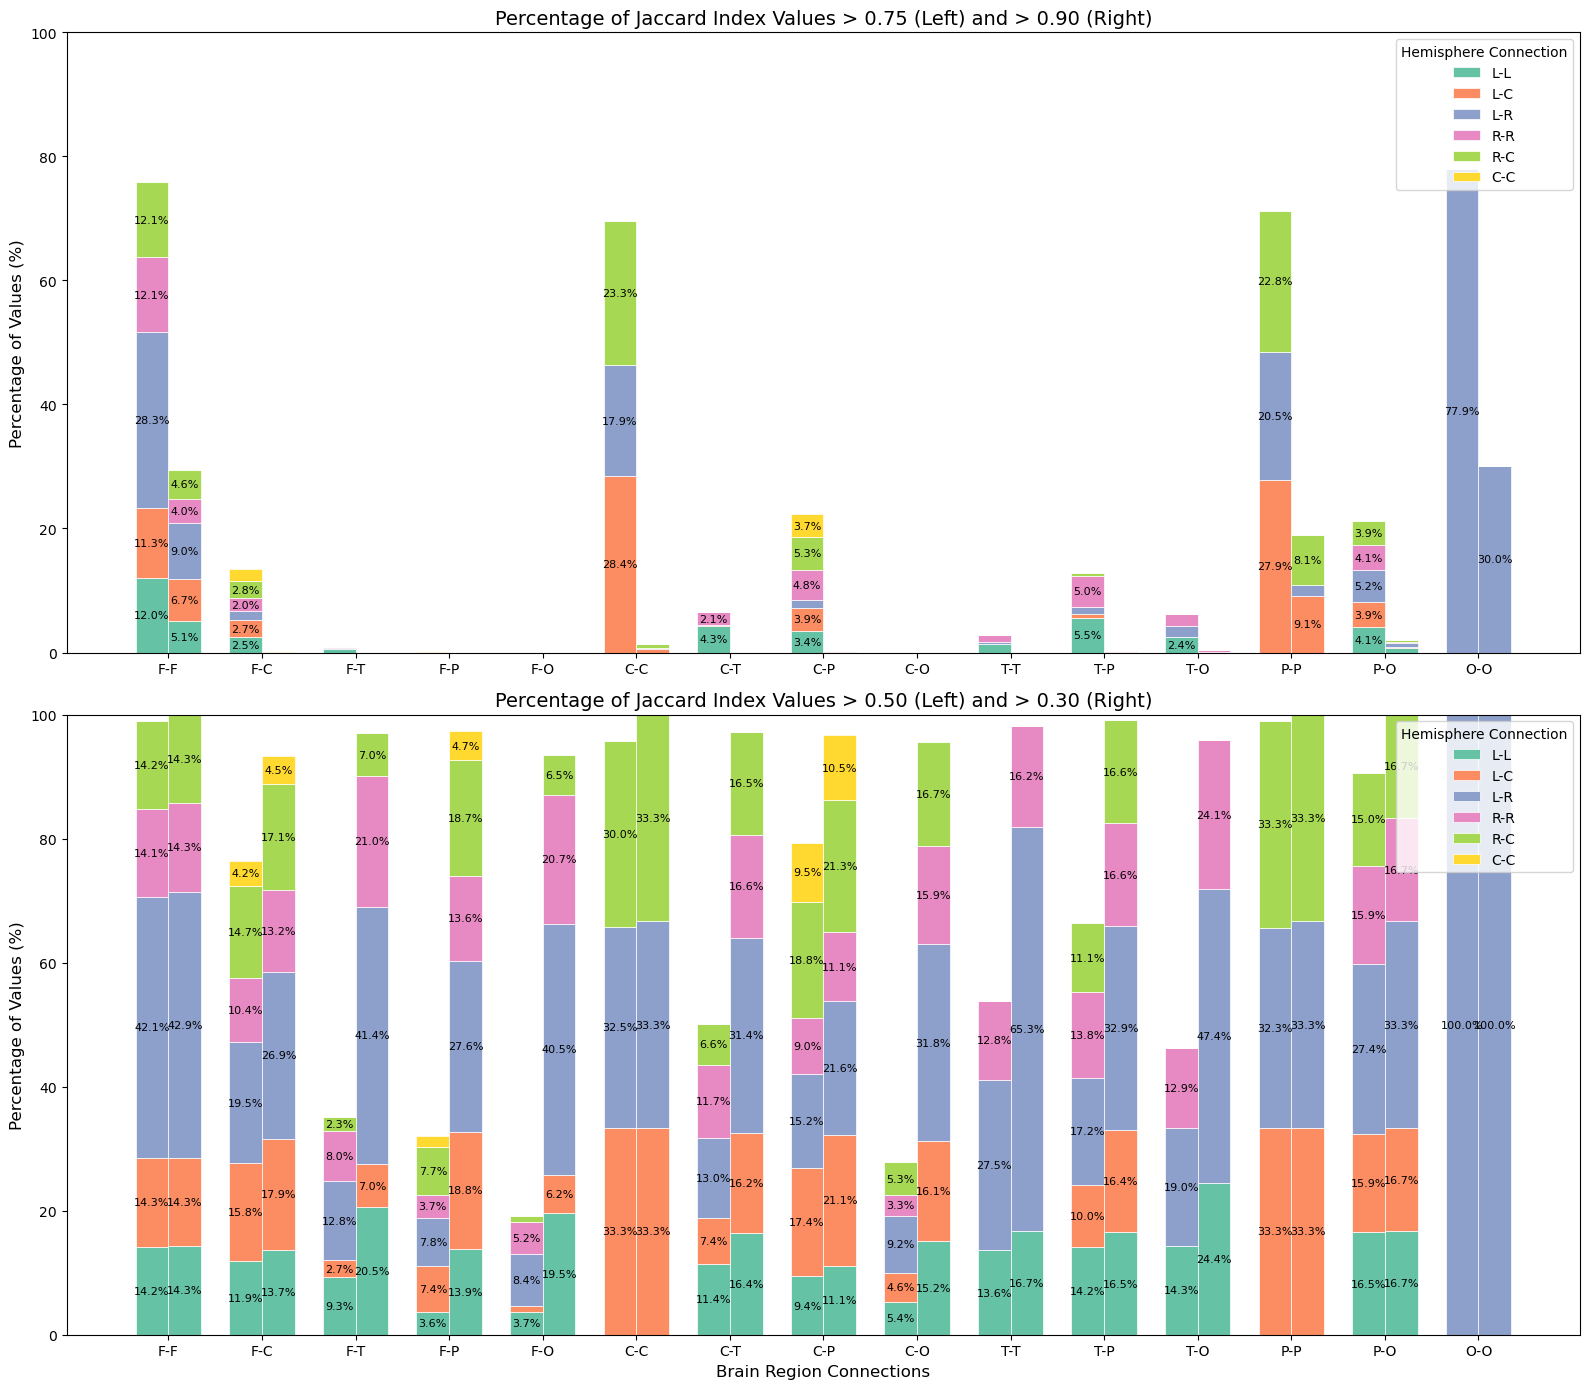

In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Load Hemisphere Labels ---
labels_df = pd.read_csv('../electrode_labels.csv') 
hemi_map = dict(zip(labels_df['channel'], labels_df['label']))

def get_hemi_pair(edge):
    u, v = edge.split('-')
    # Default to 'C' if missing just in case
    h1 = hemi_map.get(u, 'C')
    h2 = hemi_map.get(v, 'C')
    
    # Standardize order so L-R and R-L both become L-R
    order = {'L': 0, 'C': 1, 'R': 2}
    if order.get(h1, 99) <= order.get(h2, 99):
        pair = f"{h1}-{h2}"
    else:
        pair = f"{h2}-{h1}"
    
    # Rename C-R to R-C per your request
    if pair == 'C-R':
        pair = 'R-C'
    return pair

# --- 2. Define region order and canonical mapping ---
region_order = {'F': 0, 'C': 1, 'T': 2, 'P': 3, 'O': 4}

def get_region_pair(edge):
    u, v = edge.split('-')
    r1, r2 = u[0], v[0]
    if region_order.get(r1, 99) <= region_order.get(r2, 99):
        return f"{r1}-{r2}"
    else:
        return f"{r2}-{r1}"

region_groups = ['F-F', 'F-C', 'F-T', 'F-P', 'F-O',
                 'C-C', 'C-T', 'C-P', 'C-O',
                 'T-T', 'T-P', 'T-O',
                 'P-P', 'P-O',
                 'O-O']

hemi_groups = ['L-L', 'L-C', 'L-R', 'R-R', 'R-C', 'C-C']

# --- 3. Calculate percentages grouped by Region AND Hemisphere ---
stats_data = []

for cat in region_groups:
    # Find all edges belonging to this Region Pair
    edge_indices = [idx for idx, e in enumerate(edge_labels) if get_region_pair(e) == cat]
    
    # Total values across all subject pairs for this region (denominator for percentage)
    total_vals_in_region = len(edge_indices) * heatmap_data.shape[0]
    
    for hemi in hemi_groups:
        # Filter those edges further by Hemisphere Pair
        hemi_indices = [idx for idx in edge_indices if get_hemi_pair(edge_labels[idx]) == hemi]
        
        if hemi_indices and total_vals_in_region > 0:
            vals = heatmap_data[:, hemi_indices].flatten()
            # Calculate proportion relative to the entire Region Pair
            pct_30 = (np.sum(vals > 0.30) / total_vals_in_region) * 100.0
            pct_50 = (np.sum(vals > 0.50) / total_vals_in_region) * 100.0
            pct_75 = (np.sum(vals > 0.75) / total_vals_in_region) * 100.0
            pct_90 = (np.sum(vals > 0.90) / total_vals_in_region) * 100.0
        else:
            pct_30, pct_50, pct_75, pct_90 = 0.0, 0.0, 0.0, 0.0
            
        stats_data.append({'Region Pair': cat, 'Threshold': '> 0.30', 'Hemi': hemi, 'Percentage': pct_30})
        stats_data.append({'Region Pair': cat, 'Threshold': '> 0.50', 'Hemi': hemi, 'Percentage': pct_50})
        stats_data.append({'Region Pair': cat, 'Threshold': '> 0.75', 'Hemi': hemi, 'Percentage': pct_75})
        stats_data.append({'Region Pair': cat, 'Threshold': '> 0.90', 'Hemi': hemi, 'Percentage': pct_90})

df_stats = pd.DataFrame(stats_data)

# --- 4. Plot the Stacked Bar Charts ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 14))

# Pick 6 distinct colors for the 6 hemisphere regions
colors = sns.color_palette("Set2", 6) 
color_map = dict(zip(hemi_groups, colors))

x = np.arange(len(region_groups))
width = 0.35

def plot_grouped_stacked(ax, thresh1, thresh2, title):
    # thresh1
    df1 = df_stats[df_stats['Threshold'] == thresh1].pivot(index='Region Pair', columns='Hemi', values='Percentage')
    df1 = df1.reindex(index=region_groups, columns=hemi_groups).fillna(0)
    
    # thresh2
    df2 = df_stats[df_stats['Threshold'] == thresh2].pivot(index='Region Pair', columns='Hemi', values='Percentage')
    df2 = df2.reindex(index=region_groups, columns=hemi_groups).fillna(0)
    
    bottom1 = np.zeros(len(region_groups))
    bottom2 = np.zeros(len(region_groups))
    
    for hemi in hemi_groups:
        vals1 = df1[hemi].values
        vals2 = df2[hemi].values
        
        # Plot thresh1 on left
        bars1 = ax.bar(x - width/2, vals1, width, bottom=bottom1, label=hemi, color=color_map[hemi], edgecolor='white', linewidth=0.5)
        # Plot thresh2 on right (no label to avoid legend duplicates)
        bars2 = ax.bar(x + width/2, vals2, width, bottom=bottom2, color=color_map[hemi], edgecolor='white', linewidth=0.5)
        
        # Add labels
        ax.bar_label(bars1, labels=[f'{v:.1f}%' if v > 2 else '' for v in vals1], label_type='center', fontsize=8)
        ax.bar_label(bars2, labels=[f'{v:.1f}%' if v > 2 else '' for v in vals2], label_type='center', fontsize=8)
        
        bottom1 += vals1
        bottom2 += vals2

    ax.set_xticks(x)
    ax.set_xticklabels(region_groups)
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Percentage of Values (%)', fontsize=12)
    ax.set_ylim(0, 100)
    ax.legend(title='Hemisphere Connection', loc='upper right')

# --- Plot 1: > 0.75 and > 0.90 ---
plot_grouped_stacked(ax1, '> 0.75', '> 0.90', 'Percentage of Jaccard Index Values > 0.75 (Left) and > 0.90 (Right)')

# --- Plot 2: > 0.50 and > 0.30 ---
plot_grouped_stacked(ax2, '> 0.50', '> 0.30', 'Percentage of Jaccard Index Values > 0.50 (Left) and > 0.30 (Right)')

ax2.set_xlabel('Brain Region Connections', fontsize=12)

plt.tight_layout()
plt.show()
